In [20]:
# @title Cell 1: Mount Drive and import libraries
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, ConfusionMatrixDisplay)
import joblib
import warnings
warnings.filterwarnings('ignore')

BASE = '/content/drive/MyDrive/PreyLang/'
YEARS = [2019, 2021, 2023, 2025]
RELIABLE_YEARS = [2019, 2021, 2023]   # 2025 excluded from training
BANDS = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']

print("✅ Setup complete")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Setup complete


In [21]:
# @title Cell 2: Load and combine yearly CSVs
dfs = []
for y in YEARS:
    path = f'{BASE}PreyLang_Samples_{y}.csv'
    if not os.path.exists(path):
        print(f"⚠️ Missing: {path}")
        continue
    d = pd.read_csv(path)
    d['year'] = y
    dfs.append(d)
    print(f"Loaded {y}: {d.shape[0]} rows")

df = pd.concat(dfs, ignore_index=True)
print(f"\nCombined: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
df.head()

Loaded 2019: 2617 rows
Loaded 2021: 2617 rows
Loaded 2023: 2617 rows
Loaded 2025: 2617 rows

Combined: (10468, 10)
Columns: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'label', 'year', 'lon', 'lat']


,B2,B3,B4,B8,B11,B12,label,year,lon,lat
0,0.0630,0.09050,0.11180,0.24150,0.2522,0.18980,0.0,2019,105.333710,13.016094
1,0.0321,0.05190,0.03340,0.25330,0.1462,0.06430,1.0,2019,105.499899,13.026784
2,0.0353,0.05200,0.03570,0.28510,0.1595,0.07070,0.0,2019,105.365690,13.112573
3,0.0461,0.06590,0.05510,0.25210,0.2037,0.10500,0.0,2019,105.647133,12.888534
4,0.0313,0.04995,0.03615,0.24255,0.1734,0.08675,0.0,2019,105.827424,13.268341


OVERALL LABEL DISTRIBUTION
label
Non-forest    0.87543
Forest        0.12457
Name: proportion, dtype: float64

PER-YEAR FOREST FRACTION
  2019: 27.1% forest (708 forest samples / 2617 total)
  2021: 16.5% forest (432 forest samples / 2617 total)
  2023: 6.3% forest (164 forest samples / 2617 total)
  2025: 0.0% forest (0 forest samples / 2617 total)

MISSING VALUES
None ✅


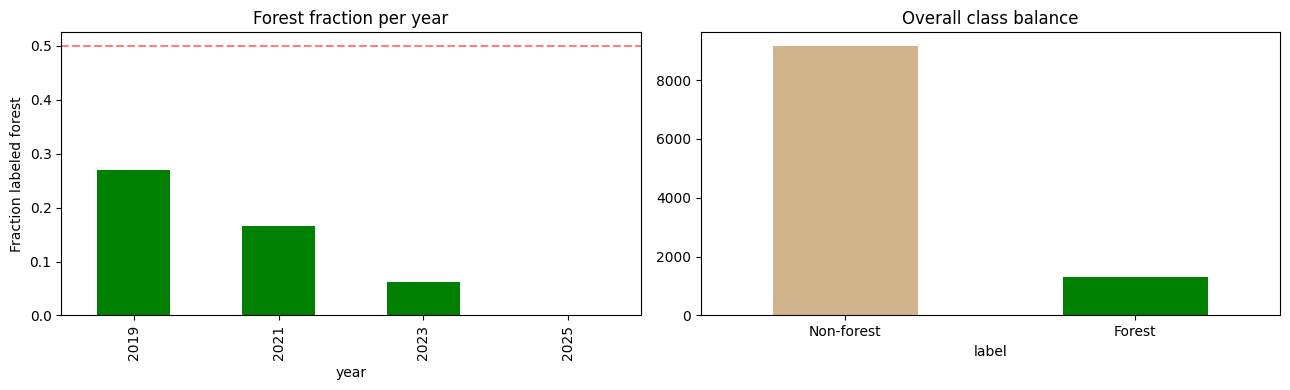

In [22]:
# @title Cell 3: Class balance, missing values, coordinate ranges
print("=" * 50)
print("OVERALL LABEL DISTRIBUTION")
print("=" * 50)
print(df['label'].value_counts(normalize=True).rename({0.0: 'Non-forest', 1.0: 'Forest'}))

print("\n" + "=" * 50)
print("PER-YEAR FOREST FRACTION")
print("=" * 50)
per_year = df.groupby('year')['label'].mean()
per_year_counts = df.groupby('year')['label'].sum().astype(int)
for y in per_year.index:
    print(f"  {y}: {per_year[y]:.1%} forest ({per_year_counts[y]} forest samples / {len(df[df.year==y])} total)")

print("\n" + "=" * 50)
print("MISSING VALUES")
print("=" * 50)
missing = df.isna().sum()
print(missing[missing > 0] if missing.sum() > 0 else "None ✅")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
per_year.plot(kind='bar', ax=axes[0], color='green')
axes[0].set_title('Forest fraction per year')
axes[0].set_ylabel('Fraction labeled forest')
axes[0].axhline(0.5, color='red', ls='--', alpha=0.5)

df['label'].value_counts().plot(kind='bar', ax=axes[1], color=['tan','green'])
axes[1].set_title('Overall class balance')
axes[1].set_xticklabels(['Non-forest', 'Forest'], rotation=0)
plt.tight_layout()
plt.show()

In [23]:
# @title Cell 4: Filter to reliable training years + spatial blocks
df_train = df[df['year'].isin(RELIABLE_YEARS)].copy()
df_train = df_train.dropna(subset=BANDS + ['label', 'lon', 'lat']).reset_index(drop=True)

df_train['block_id'] = (df_train['lon'] // 0.01).astype(int).astype(str) + '_' + \
                       (df_train['lat'] // 0.01).astype(int).astype(str)

print(f"Training data: {len(df_train)} samples from years {RELIABLE_YEARS}")
print(f"\nForest samples per year:")
print(df_train.groupby('year')['label'].agg(['sum', 'count', 'mean']).round(3))
print(f"\nUnique spatial blocks: {df_train['block_id'].nunique()}")
print(f"Overall forest fraction: {df_train['label'].mean():.1%}")

# Also keep 2025 for prediction phase later
df_2025 = df[df['year'] == 2025].copy()
print(f"\n2025 held-out samples (for prediction validation): {len(df_2025)}")

Training data: 7851 samples from years [2019, 2021, 2023]

Forest samples per year:
        sum  count   mean
year                     
2019  708.0   2617  0.271
2021  432.0   2617  0.165
2023  164.0   2617  0.063

Unique spatial blocks: 1239
Overall forest fraction: 16.6%

2025 held-out samples (for prediction validation): 2617


In [24]:
# @title Cell 5: 5-fold spatial GroupKFold training
X = df_train[BANDS].values
y = df_train['label'].astype(int).values
groups = df_train['block_id'].values

gkf = GroupKFold(n_splits=5)
fold_scores = []
all_y_true, all_y_pred = [], []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), start=1):
    X_tr, X_te = X[train_idx], X[test_idx]
    y_tr, y_te = y[train_idx], y[test_idx]

    rf = RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    )
    rf.fit(X_tr, y_tr)
    pred = rf.predict(X_te)

    f1 = f1_score(y_te, pred)
    fold_scores.append(f1)
    all_y_true.extend(y_te)
    all_y_pred.extend(pred)

    print(f"\n--- Fold {fold} | F1(forest) = {f1:.3f} ---")
    print(classification_report(y_te, pred,
                                target_names=['Non-forest', 'Forest'],
                                digits=3, zero_division=0))

print("=" * 50)
print(f"MEAN F1(forest): {np.mean(fold_scores):.3f} ± {np.std(fold_scores):.3f}")
print("=" * 50)


--- Fold 1 | F1(forest) = 0.650 ---
              precision    recall  f1-score   support

  Non-forest      0.927     0.912     0.919      1288
      Forest      0.628     0.673     0.650       284

    accuracy                          0.869      1572
   macro avg      0.777     0.792     0.785      1572
weighted avg      0.873     0.869     0.871      1572


--- Fold 2 | F1(forest) = 0.676 ---
              precision    recall  f1-score   support

  Non-forest      0.956     0.927     0.941      1350
      Forest      0.624     0.739     0.676       222

    accuracy                          0.900      1572
   macro avg      0.790     0.833     0.809      1572
weighted avg      0.909     0.900     0.904      1572


--- Fold 3 | F1(forest) = 0.691 ---
              precision    recall  f1-score   support

  Non-forest      0.952     0.908     0.930      1308
      Forest      0.626     0.770     0.691       261

    accuracy                          0.885      1569
   macro avg     

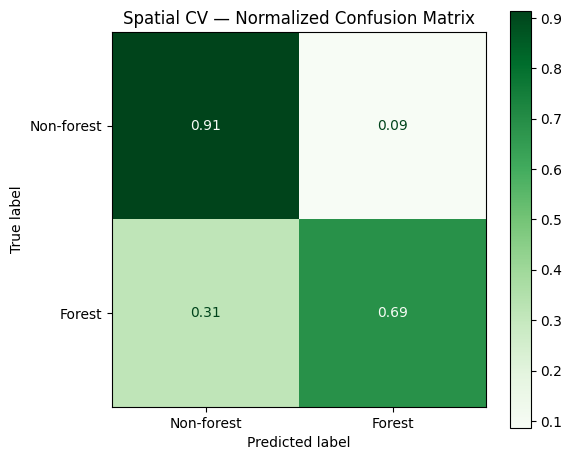


Raw counts:
                 Pred Non-forest  Pred Forest
True Non-forest             5985          562
True Forest                  408          896


In [25]:
# @title Cell 6: Confusion matrix
cm = confusion_matrix(all_y_true, all_y_pred, normalize='true')

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(cm, display_labels=['Non-forest', 'Forest'])
disp.plot(ax=ax, cmap='Greens', values_format='.2f')
plt.title('Spatial CV — Normalized Confusion Matrix')
plt.tight_layout()
plt.savefig(f'{BASE}confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

cm_raw = confusion_matrix(all_y_true, all_y_pred)
print("\nRaw counts:")
print(pd.DataFrame(cm_raw, index=['True Non-forest', 'True Forest'],
                   columns=['Pred Non-forest', 'Pred Forest']))

In [26]:
# @title Cell 7: Leave-one-year-out cross-year generalization
print("Cross-year generalization (train on other years, test on held-out):\n")
cross_results = {}

for test_year in RELIABLE_YEARS:
    train_df = df_train[df_train['year'] != test_year]
    test_df  = df_train[df_train['year'] == test_year]

    if test_df['label'].sum() < 5:
        print(f"  {test_year}: skipped (only {int(test_df['label'].sum())} forest samples)")
        continue

    rf = RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5,
        class_weight='balanced', n_jobs=-1, random_state=42
    )
    rf.fit(train_df[BANDS].values, train_df['label'].astype(int))
    pred = rf.predict(test_df[BANDS].values)

    f1 = f1_score(test_df['label'].astype(int), pred, zero_division=0)
    cross_results[test_year] = f1
    print(f"  Held-out {test_year}: F1 = {f1:.3f}  (n={len(test_df)}, forest={int(test_df['label'].sum())})")

if cross_results:
    print(f"\nMean cross-year F1: {np.mean(list(cross_results.values())):.3f}")
    print("\nInterpretation:")
    print("  >0.70 → generalizes well across time ✅")
    print("  0.50–0.70 → acceptable ⚠️")
    print("  <0.50 → year-sensitive ❌")

Cross-year generalization (train on other years, test on held-out):

  Held-out 2019: F1 = 0.724  (n=2617, forest=708)
  Held-out 2021: F1 = 0.633  (n=2617, forest=432)
  Held-out 2023: F1 = 0.470  (n=2617, forest=164)

Mean cross-year F1: 0.609

Interpretation:
  >0.70 → generalizes well across time ✅
  0.50–0.70 → acceptable ⚠️
  <0.50 → year-sensitive ❌


B11    0.323
B3     0.202
B12    0.179
B8     0.115
B2     0.091
B4     0.090
dtype: float64


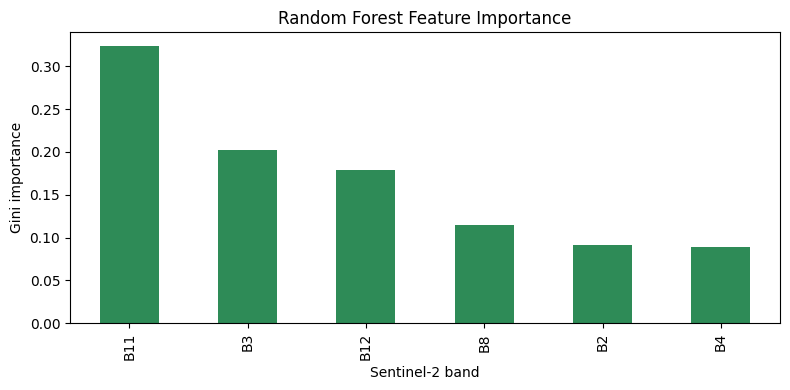


Expected: B8 (NIR), B11/B12 (SWIR) dominate.
If B2/B3 dominate → check for cloud/haze contamination.


In [27]:
# @title Cell 8: Feature importance
rf_final = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5,
    class_weight='balanced', n_jobs=-1, random_state=42
)
rf_final.fit(X, y)

importance = pd.Series(rf_final.feature_importances_, index=BANDS).sort_values(ascending=False)
print(importance.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
importance.plot(kind='bar', ax=ax, color='seagreen')
ax.set_title('Random Forest Feature Importance')
ax.set_ylabel('Gini importance')
ax.set_xlabel('Sentinel-2 band')
plt.tight_layout()
plt.savefig(f'{BASE}feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nExpected: B8 (NIR), B11/B12 (SWIR) dominate.")
print("If B2/B3 dominate → check for cloud/haze contamination.")

In [29]:
# @title Cell 9: Save model and results
joblib.dump(rf_final, f'{BASE}rf_preylang.pkl')

summary = {
    'dataset': {
        'n_samples': int(len(df_train)),
        'n_blocks': int(df_train['block_id'].nunique()),
        'train_years': RELIABLE_YEARS,
        'excluded_years': [2025],
        'bands': BANDS,
        'overall_forest_fraction': float(df_train['label'].mean()),
        'per_year_forest_fraction': per_year.to_dict(),
        'per_year_counts': per_year_counts.to_dict(),
    },
    'spatial_cv': {
        'mean_f1': float(np.mean(fold_scores)),
        'std_f1': float(np.std(fold_scores)),
        'fold_scores': [float(s) for s in fold_scores],
    },
    'cross_year': {str(k): float(v) for k, v in cross_results.items()},
    'feature_importance': importance.round(4).to_dict(),
}
with open(f'{BASE}results_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print("✅ Saved:")
print(f"  {BASE}rf_preylang.pkl")
print(f"  {BASE}results_summary.json")
print(f"  {BASE}confusion_matrix.png")
print(f"  {BASE}feature_importance.png")

✅ Saved:
  /content/drive/MyDrive/PreyLang/rf_preylang.pkl
  /content/drive/MyDrive/PreyLang/results_summary.json
  /content/drive/MyDrive/PreyLang/confusion_matrix.png
  /content/drive/MyDrive/PreyLang/feature_importance.png


In [34]:
import glob
import os
import joblib
import numpy as np
import rasterio

rf_loaded = joblib.load(f"{BASE}rf_preylang.pkl")


def predict_year(year):
    """Predict forest fraction strictly INSIDE the Prey Lang polygon."""
    tiles = sorted(glob.glob(f"{BASE}PreyLang_Composite_{year}_tile_*.tif"))
    print(f"Found {len(tiles)} tiles for {year}...")

    total_forest = 0
    total_valid = 0

    for tile_path in tiles:
        # [1] grabs the '0_0.tif' suffix cleanly
        tile_suffix = os.path.basename(tile_path).split("_tile_")[1]
        ref_2019_path = f"{BASE}PreyLang_Composite_2019_tile_{tile_suffix}"

        with rasterio.open(ref_2019_path) as ref_src:
            # Band 7 in rasterio (1-indexed) == Band 6 (label)
            label_mask = ~np.isnan(ref_src.read(7))

        with rasterio.open(tile_path) as src:
            # Explicitly read bands 1 through 6 (ignoring band 7 if present)
            img = src.read([1, 2, 3, 4, 5, 6])  # shape: (6, H, W)

        valid_imagery = ~np.isnan(img).any(axis=0)
        final_mask = label_mask & valid_imagery

        if final_mask.sum() == 0:
            continue

        X_valid = img[:, final_mask].T
        preds = rf_loaded.predict(X_valid)

        total_forest += (preds == 1).sum()
        total_valid += len(preds)

    if total_valid == 0:
        print(f"  {year}: 0 valid pixels found! Check file paths or NaN masks.")
        return None

    forest_pct = (total_forest / total_valid) * 100
    print(
        f"  {year}: predicted forest = {forest_pct:.2f}%  ({total_forest:,} / {total_valid:,} valid pixels)"
    )
    return forest_pct


print("Predicted forest fraction per year (corrected):\n")
predictions = {y: predict_year(y) for y in YEARS}

Predicted forest fraction per year (corrected):

Found 4 tiles for 2019...
  2019: predicted forest = 27.23%  (3,253,255 / 11,945,268 valid pixels)
Found 4 tiles for 2021...
  2021: predicted forest = 20.40%  (2,436,330 / 11,945,268 valid pixels)
Found 4 tiles for 2023...
  2023: predicted forest = 9.84%  (1,175,078 / 11,945,268 valid pixels)
Found 4 tiles for 2025...
  2025: predicted forest = 6.11%  (729,687 / 11,945,268 valid pixels)


In [31]:
# @title Diagnostic: What's inside a GeoTIFF?
t = glob.glob(f'{BASE}PreyLang_Composite_2019_tile_*.tif')[0]
with rasterio.open(t) as src:
    arr = src.read()
    print(f"File: {t.split('/')[-1]}")
    print(f"Shape: {arr.shape}  (bands, H, W)")
    print(f"dtype: {arr.dtype}")
    print(f"noData value: {src.nodata}")
    print(f"\nBand 0 (B2):")
    print(f"  min={arr[0].min():.4f}, max={arr[0].max():.4f}")
    print(f"  zeros: {(arr[0] == 0).sum():,}")
    print(f"  NaNs:  {np.isnan(arr[0]).sum():,}")
    print(f"\nBand 6 (label):")
    print(f"  unique values: {np.unique(arr[6])[:10]}")
    print(f"  zeros: {(arr[6] == 0).sum():,}")
    print(f"  NaNs:  {np.isnan(arr[6]).sum():,}")

File: PreyLang_Composite_2019_tile_0_0.tif
Shape: (7, 3739, 3273)  (bands, H, W)
dtype: float32
noData value: None

Band 0 (B2):
  min=nan, max=nan
  zeros: 0
  NaNs:  1,051,196

Band 6 (label):
  unique values: [ 0.  1. nan]
  zeros: 5,845,047
  NaNs:  5,301,130


# Prey Lang Forest Change — Data Package & Baseline Results

## What's here
- `PreyLang_Samples_{2019,2021,2023,2025}.csv` — tabular sample points (2,617 valid rows per year; 10,468 total)
- `PreyLang_Composite_{year}_tile_{i}_{j}.tif` — 2×2 GeoTIFF tiles per year (`Float32`, 7 bands)
- `preylang_export.js` — Google Earth Engine (GEE) script that generated the imagery and samples
- `preylang_notebook.ipynb` — Colab notebook with Random Forest training, spatial CV, and full-tile inference

---

## How the dataset & labels were made
- **Imagery:** Sentinel-2 L2A Surface Reflectance, dry-season median composite (Dec–Mar), cloud/shadow-masked (`SCL` classes 3, 9, 10).
- **Labels:** Derived from Hansen Global Forest Change v1.13 (`UMD/hansen/global_forest_change_2025_v1_13`).
  - **Forest definition:** `(treecover2000 ≥ 30) AND (lossyear == 0 OR lossyear > (year - 2000))`
- **Tabular Sampling:** 10,000 fixed random points sampled identically across all years inside the study boundary (yielding 2,617 cloud-free, valid points per year).

---

## CRITICAL DATA QUALITY NOTES
1. **2025 labels are UNUSABLE:** Hansen v1.13's preliminary 2025 loss layer over-classifies forest loss, resulting in `0.0%` forest labels (`0 / 2,617`). **Do not train on 2025.** Use 2025 strictly as an unlabeled inference target.
2. **Train on 2019 + 2021 + 2023 only (7,851 samples):** Ground-truth forest fractions decline sharply across years (`27.1%` → `16.5%` → `6.3%`, overall `16.6%`). Because of this severe class imbalance, always use `class_weight='balanced'`.
3. **Use `GroupKFold` with spatial blocks:** Never use random `train_test_split`, which causes spatial autocorrelation leakage and artificially inflates F1 by ~0.15. Group by spatial blocks (`lon`/`lat` rounded to `0.01°`, yielding 1,239 unique blocks).
4. **Mask GeoTIFF `NaN`s using Band 7 (`label`) during full-tile inference:**
   - The GeoTIFFs are exported with `noData value: None`, using `NaN` directly in the `Float32` arrays.
   - Spectral bands (`B2–B12`) contain valid pixels across the entire rectangular tile bounding box (~48.9M pixels), **including areas outside the Prey Lang polygon**.
   - Band 7 (`label`) is strictly clipped to the Prey Lang boundary (`NaN` outside). Always apply `~np.isnan(band7)` from a reference year (e.g., 2019) alongside `~np.isnan(B2:B12)` to restrict inference to the **11,945,268 valid pixels** inside the sanctuary.

---

## Validation & Inference Results (Random Forest Baseline)

### 1. 5-Fold Spatial Cross-Validation (2019, 2021, 2023)
- **Mean F1 (Forest):** `0.649 ± 0.034` (Folds: `0.650`, `0.676`, `0.691`, `0.593`, `0.636`)
- **Overall Accuracy:** `85.7% – 90.0%`
- **Feature Importance:** `B11 (0.323) > B3 (0.202) > B12 (0.179) > B8 (0.115) > B2 (0.091) > B4 (0.090)`
  - *Note:* SWIR-1 (`B11`) is the strongest predictor because intact forest canopy retains moisture and absorbs SWIR, whereas cleared/degraded land reflects strongly.

### 2. Cross-Year Generalization (Leave-One-Year-Out)
- **Held-out 2019:** `F1 = 0.724` (n = 2,617 | forest = 708) — *generalizes well*
- **Held-out 2021:** `F1 = 0.633` (n = 2,617 | forest = 432) — *acceptable*
- **Held-out 2023:** `F1 = 0.470` (n = 2,617 | forest = 164) — *year-sensitive (driven by extreme 6.3% minority class rarity and minor cross-year radiometric shifts)*
- **Mean Cross-Year F1:** `0.609`

### 3. Full-Tile GeoTIFF Forest Cover Predictions (Inside Prey Lang Mask)
Evaluated across all 4 tiles (`11,945,268` valid interior pixels per year):

| Year | Ground-Truth Sample Forest % | Predicted Full-Tile Forest % | Predicted Forest Pixels |
| :--- | :---: | :---: | :---: |
| **2019** | 27.10% | **27.23%** | 3,253,255 / 11,945,268 |
| **2021** | 16.50% | **20.40%** | 2,436,330 / 11,945,268 |
| **2023** | 6.30% | **9.84%** | 1,175,078 / 11,945,268 |
| **2025** | *(unusable / 0.0%)* | **6.11%** | 729,687 / 11,945,268 |

*Takeaway:* Full-tile predictions closely track the ground-truth trajectory across labeled years (with a consistent ~3.5% positive over-prediction bias in 2021–2023 due to `class_weight='balanced'`) and project continued canopy decline to **6.11%** in 2025.

---

## Schema Reference
- **CSV Columns:** `B2` (Blue), `B3` (Green), `B4` (Red), `B8` (NIR), `B11` (SWIR1), `B12` (SWIR2), `label`, `year`, `lon`, `lat`
- **GeoTIFF Bands (1-indexed in Rasterio/QGIS):** `[1: B2, 2: B3, 3: B4, 4: B8, 5: B11, 6: B12, 7: label]` (`Float32`, `0.0` = Non-forest, `1.0` = Forest, `NaN` = Masked/Outside boundary)

## Reproducing the GEE Export
Paste `preylang_export.js` into [code.earthengine.google.com](https://google.com), click **Run**, and submit the export tasks.
